# Dichotic left: overt and masked onsets, intensity-level control

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Overt and masked onsets** are made with each speaker at its level in the mixture that was played
(`predictors/inmix_onsets.py`; the speakers' own files are 4x louder, which made part of every
onset look masked). The split is tested against the same onsets unsplit (`FULL_INMIX`).

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('dichotic_left_overt_masked_onsets')

7 of 7 results this notebook reads are not on the cluster yet; asking the cluster for them.
Submitted job 9239240 for dichotic_left_overt_masked_onsets. Follow it with cluster_queue(); the cluster also emails when it ends.
Waiting for job 9239240 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  22:21  9239240 pending  (0 min so far)
  22:30  9239240 running  (8 min so far)
Job 9239240 is done: all 7 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 
        9239211     iggy def-ibruce_c cocktail-dicho   R 1-23:23:39     1   32        N/A    128G nc30411 (None) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-dichotic_left_overt_masked_onsets-9239240.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:29:51 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-12 22:30:35 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components select

## Dichotic Left (overt onsets)

In [ ]:
# The ROI this notebook uses, imported from roi.txt: the clean-speech notebook found it
# from its onset and envelope test - baseline topomaps.
ROI = show_roi('dichotic_left_overt_masked_onsets')

In [ ]:
# Overt/masked split vs. plain onsets (dichotic-left)
# overt/masked = the split of each speaker's onsets into the part still visible in the mixture and
# the part the other speaker covers, with the speaker at its level in the mixture.
# Brodbeck et al. 2020 ran this comparison too: splitting onsets into overt/masked significantly improved the model overall, t = 6.81, p < .001.

# FULL_INMIX  = Eatt + Oatt + Eign + Oign + Emix + Omix   (Oatt, Oign at their level in the mixture)
# FULL_MASKED = Eatt + Oatt_overt + Oatt_masked + Eign + Oign_overt + Oign_masked + Emix + Omix
#
# Comparison: FULL_MASKED > FULL_INMIX
#   (does splitting Oatt/Oign into overt + masked improve the fit? overt + masked == Oatt/Oign,
#   so the two models carry the same onsets, only split or not)
#
# Full predictor names:
# FULL_MASKED (test model):
#   gammatone-8 + gammatone-on-overt-inmix-8 + gammatone-on-masked-inmix-8
#   + bg~gammatone-8 + bg~gammatone-on-overt-inmix-8 + bg~gammatone-on-masked-inmix-8
#   + mix~gammatone-8 + mix~gammatone-on-8
#
# FULL_INMIX (baseline model):
#   gammatone-8 + gammatone-on-inmix-8
#   + bg~gammatone-8 + bg~gammatone-on-inmix-8
#   + mix~gammatone-8 + mix~gammatone-on-8

data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_INMIX, 'dichotic-left')
show_topomap_trio(data, diff, result, 'Overt/masked split vs. plain onsets', 'dichotic-left', None)

In [6]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt/masked split vs. plain onsets (dichotic-left): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 4 clusters, p = .060>

Overt/masked split vs. plain onsets (dichotic-left): ROI model comparison t(12) = 1.357, p = 0.0998


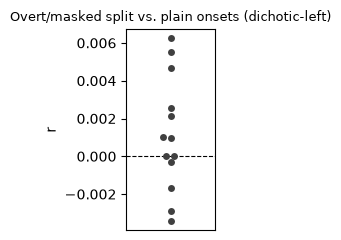

In [7]:
p = show_subject_swarm(diff, 'Overt/masked split vs. plain onsets', 'dichotic-left')

In [8]:
# Loaded once here, reused by every STRF/peak/waveform/attention-
# effect/masking-comparison cell in both this subsection and "masked
# onset" below - same reasoning as data_full above, for FULL_MASKED.
data_masked = load_trfs_saved(FULL_MASKED, 'dichotic-left')

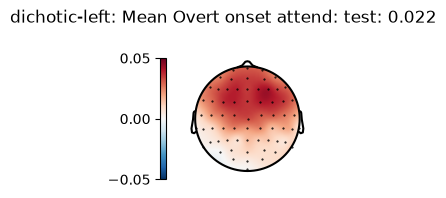

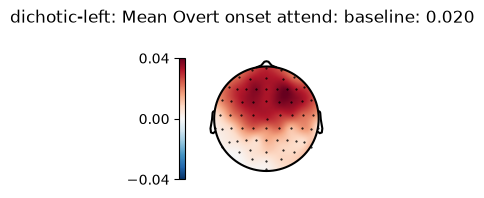

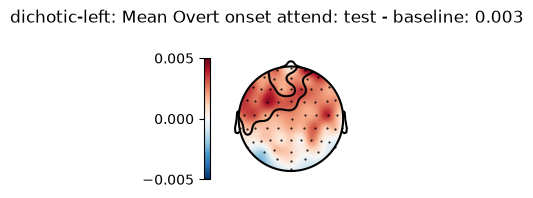

In [9]:
# Overt onset attend unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: attended overt onsets unique contribution, t = 3.34, p = .027.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(ATTEND), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Overt onset attend', 'dichotic-left', overt_onset(ATTEND))

In [10]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset attend (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 3 clusters, p = .045>

Overt onset attend (dichotic-left): ROI unique contribution t(12) = 2.070, p = 0.0303


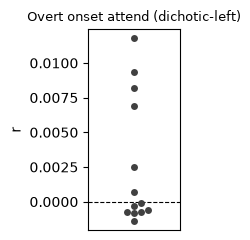

In [11]:
p = show_subject_swarm(diff, 'Overt onset attend', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


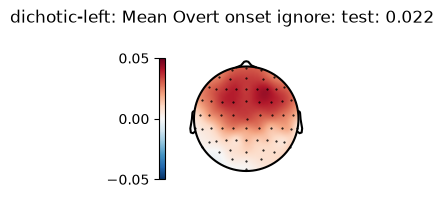

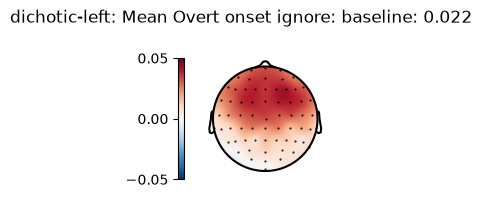

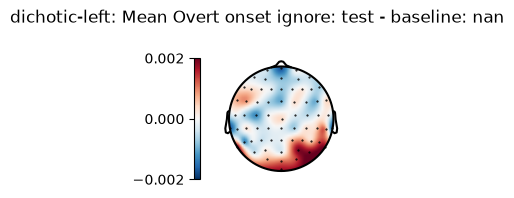

In [12]:
# Overt onset ignore unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: ignored overt onsets unique contribution, t = 3.82, p = .016.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(IGNORE), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Overt onset ignore', 'dichotic-left', overt_onset(IGNORE))

In [13]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset ignore (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 1 clusters, p = .571>

Overt onset ignore (dichotic-left): ROI unique contribution t(12) = -1.027, p = 0.8377


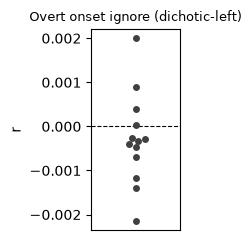

In [14]:
p = show_subject_swarm(diff, 'Overt onset ignore', 'dichotic-left')

In [ ]:
# Overt onset attend STRF (dichotic-left)
strf = extract_strf(data_masked, 'gammatone_on_overt_inmix_8')
p = plot.Array(strf * 1e3, title='Overt onset attend STRF (dichotic-left)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [ ]:
# Overt onset ignore STRF (dichotic-left)
strf = extract_strf(data_masked, 'bg_gammatone_on_overt_inmix_8')
p = plot.Array(strf * 1e3, title='Overt onset ignore STRF (dichotic-left)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [ ]:
# Overt onset attend peak amplitude & timing (dichotic-left)
data = extract_trf(data_masked, 'gammatone_on_overt_inmix_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset attend (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset attend (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Overt onset attend TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_masked, 'gammatone_on_overt_inmix_8', 'Overt onset attend TRF (dichotic-left)')

In [ ]:
# Overt onset ignore peak amplitude & timing (dichotic-left)
data = extract_trf(data_masked, 'bg_gammatone_on_overt_inmix_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset ignore (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset ignore (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Overt onset ignore TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_masked, 'bg_gammatone_on_overt_inmix_8', 'Overt onset ignore TRF (dichotic-left)')

In [ ]:
# Overt onset peak comparison across attend and ignore (dichotic-left)
dss = []
for role_name, column in (('attend', 'gammatone_on_overt_inmix_8'), ('ignore', 'bg_gammatone_on_overt_inmix_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

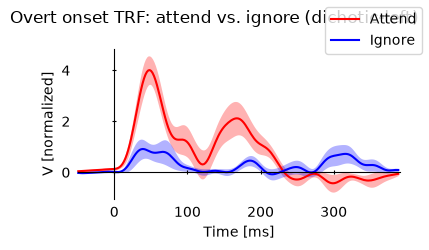

In [22]:
# The overt onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt onset TRF: attend vs. ignore (dichotic-left)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [23]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              58      0.003358
02        attend              48      0.002687
03        attend              45      0.001485
04        attend              41      0.002621
05        attend              41      0.008541
06        attend              45       0.00295
07        attend              54      0.007372
08        attend              43      0.006944
09        attend              56      0.007618
10        attend              50      0.004131
11        attend              50      0.002984
12        attend              41      0.004829
13        attend              54      0.003685
01        ignore              56     0.0009177
02        ignore              52     0.0004424
03        ignore              41     0.0005438
04        ignore              41     0.0004296
05        ignore              58      0.001038
06        ignore              41      0.004097
07        ignore              45     6.393e-0

In [24]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='overt onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='overt onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -0.20 p = .847


,ignore
attend,t12 = -6.81*** p < .001


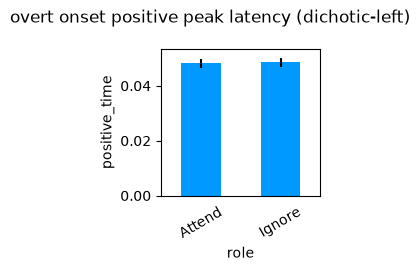

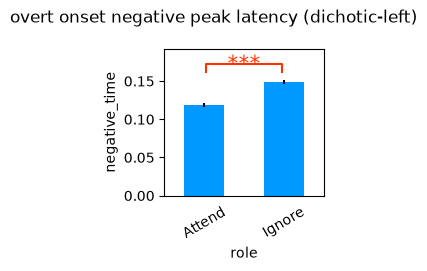

In [25]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak latency (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak latency (dichotic-left)')
p.set_xtick_rotation(30)

In [26]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='overt onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='overt onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 3.93** p = .002


,ignore
attend,t12 = 0.32 p = .753


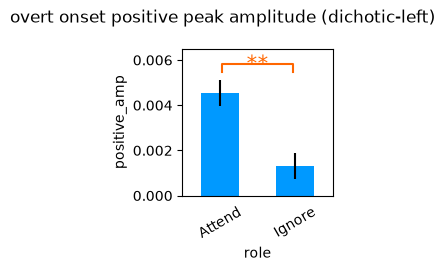

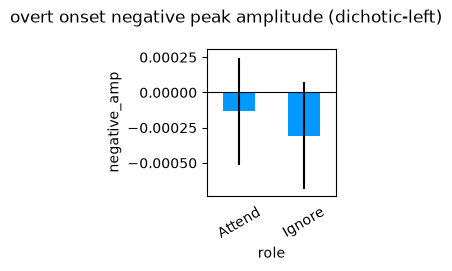

In [27]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)

In [ ]:
# Overt onset attention effect: attend - ignore (dichotic-left)
p = plot_trf_bins(data_masked, 'gammatone_on_overt_inmix_8', 'Overt onset attention effect: attend - ignore (dichotic-left)', subtract='bg_gammatone_on_overt_inmix_8')

## Dichotic Left (masked onset)

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


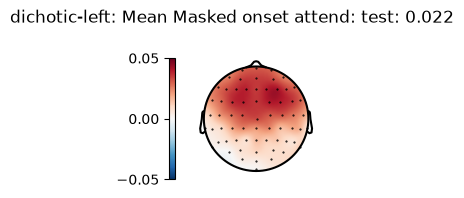

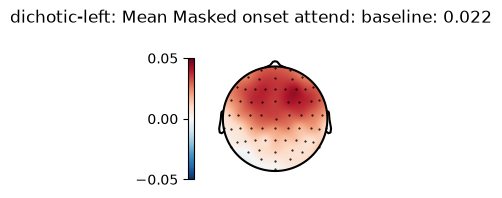

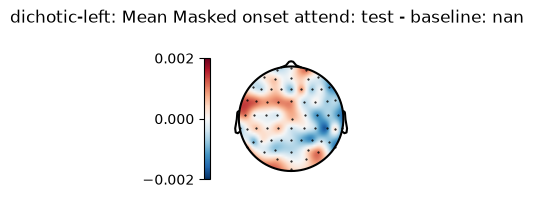

In [29]:
# Masked onset attend unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: attended masked onsets unique contribution, t = 8.42, p < .001 - the strongest of the four masking predictors.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(ATTEND), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Masked onset attend', 'dichotic-left', masked_onset(ATTEND))

In [30]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset attend (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, no clusters>

Masked onset attend (dichotic-left): ROI unique contribution t(12) = 0.093, p = 0.4636


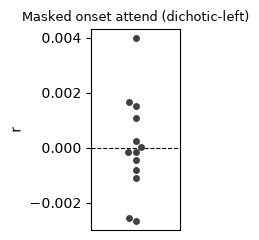

In [31]:
p = show_subject_swarm(diff, 'Masked onset attend', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


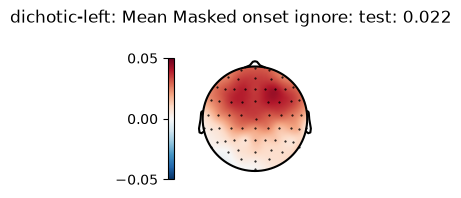

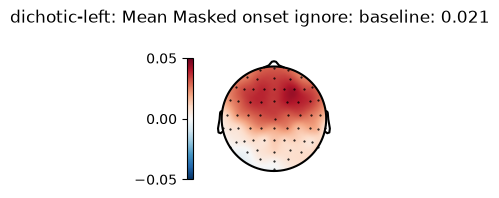

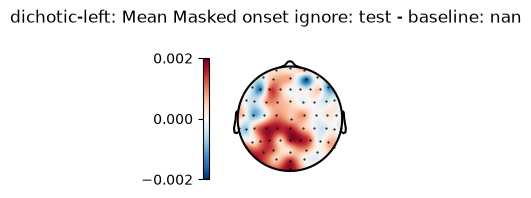

In [32]:
# Masked onset ignore unique contribution (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: ignored masked onsets unique contribution, t = 5.23, p < .001 - the brain recovers masked information even for the ignored speaker.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(IGNORE), 'dichotic-left')
show_topomap_trio(data, diff, result, 'Masked onset ignore', 'dichotic-left', masked_onset(IGNORE))

In [33]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset ignore (dichotic-left): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 2 clusters, p = .264>

Masked onset ignore (dichotic-left): ROI unique contribution t(12) = 0.324, p = 0.3756


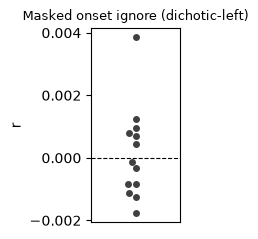

In [34]:
p = show_subject_swarm(diff, 'Masked onset ignore', 'dichotic-left')

In [ ]:
# Masked onset attend STRF (dichotic-left)
strf = extract_strf(data_masked, 'gammatone_on_masked_inmix_8')
p = plot.Array(strf * 1e3, title='Masked onset attend STRF (dichotic-left)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [ ]:
# Masked onset ignore STRF (dichotic-left)
strf = extract_strf(data_masked, 'bg_gammatone_on_masked_inmix_8')
p = plot.Array(strf * 1e3, title='Masked onset ignore STRF (dichotic-left)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [ ]:
# Masked onset attend peak amplitude & timing (dichotic-left)
data = extract_trf(data_masked, 'gammatone_on_masked_inmix_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset attend (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset attend (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Masked onset attend TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_masked, 'gammatone_on_masked_inmix_8', 'Masked onset attend TRF (dichotic-left)')

In [ ]:
# Masked onset ignore peak amplitude & timing (dichotic-left)
data = extract_trf(data_masked, 'bg_gammatone_on_masked_inmix_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset ignore (dichotic-left) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset ignore (dichotic-left) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

In [ ]:
# Masked onset ignore TRF per frequency bin (dichotic-left)
p = plot_trf_bins(data_masked, 'bg_gammatone_on_masked_inmix_8', 'Masked onset ignore TRF (dichotic-left)')

In [ ]:
# Masked onset peak comparison across attend and ignore (dichotic-left)
dss = []
for role_name, column in (('attend', 'gammatone_on_masked_inmix_8'), ('ignore', 'bg_gammatone_on_masked_inmix_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

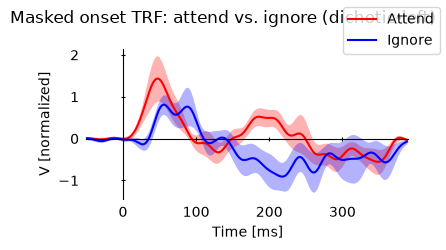

In [42]:
# The masked onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Masked onset TRF: attend vs. ignore (dichotic-left)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [43]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              70      0.000183
02        attend              54      0.001738
03        attend              70     0.0001787
04        attend              41     0.0005805
05        attend              45      0.007308
06        attend              45      0.002747
07        attend              54     0.0007166
08        attend              52      0.002382
09        attend              70      0.001038
10        attend              52      0.001539
11        attend              45       0.00169
12        attend              41     0.0008035
13        attend              70     9.472e-05
01        ignore              64      0.001873
02        ignore              56     0.0008053
03        ignore              66      0.002325
04        ignore              76     0.0002339
05        ignore              56      0.002163
06        ignore              45      0.002183
07        ignore              80      0.00418

In [44]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='masked onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='masked onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = -2.35* p = .036


,ignore
attend,t12 = -8.33*** p < .001


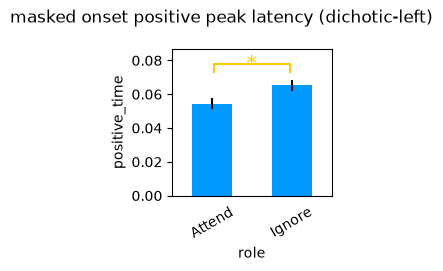

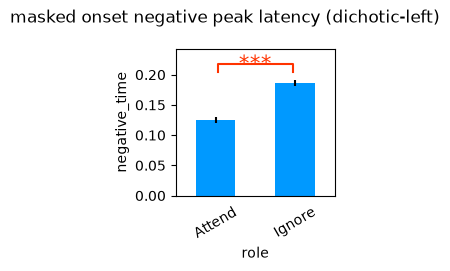

In [45]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak latency (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak latency (dichotic-left)')
p.set_xtick_rotation(30)

In [46]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='masked onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='masked onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 0.39 p = .704


,ignore
attend,t12 = 0.48 p = .637


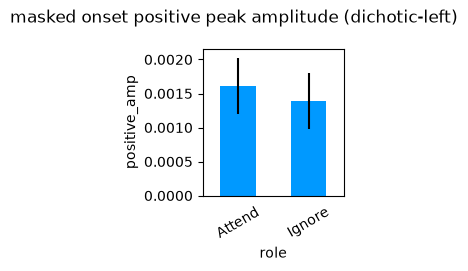

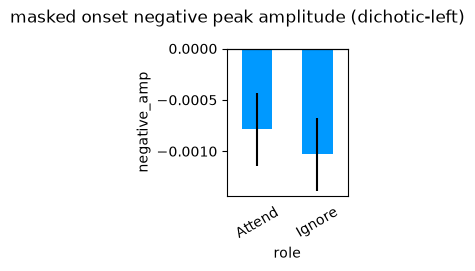

In [47]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak amplitude (dichotic-left)')
p.set_xtick_rotation(30)

In [ ]:
# Masked onset attention effect: attend - ignore (dichotic-left)
p = plot_trf_bins(data_masked, 'gammatone_on_masked_inmix_8', 'Masked onset attention effect: attend - ignore (dichotic-left)', subtract='bg_gammatone_on_masked_inmix_8')

In [ ]:
# Overt vs. masked peak comparison, attend (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: attended overt 72ms vs. attended masked 91ms (t=2.85,p=.009); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'gammatone_on_overt_inmix_8'), ('masked', 'gammatone_on_masked_inmix_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

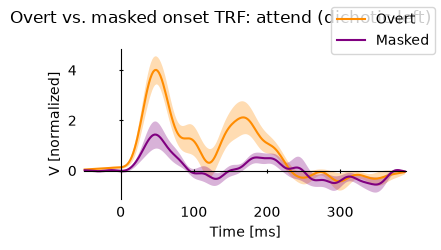

In [50]:
# Overt and masked onset TRFs of the attended speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: attend (dichotic-left)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [51]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               58      0.003358
02        overt               48      0.002687
03        overt               45      0.001485
04        overt               41      0.002621
05        overt               41      0.008541
06        overt               45       0.00295
07        overt               54      0.007372
08        overt               43      0.006944
09        overt               56      0.007618
10        overt               50      0.004131
11        overt               50      0.002984
12        overt               41      0.004829
13        overt               54      0.003685
01        masked              70      0.000183
02        masked              54      0.001738
03        masked              70     0.0001787
04        masked              41     0.0005805
05        masked              45      0.007308
06        masked              45      0.002747
07        masked              54     0.000716

In [52]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='attend positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='attend negative peak latency: overt vs. masked'))

,masked
overt,t12 = -2.66* p = .021


,masked
overt,t12 = -1.09 p = .297


In [53]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='attend positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='attend negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = 5.09*** p < .001


,masked
overt,t12 = 1.43 p = .178


In [ ]:
# Overt vs. masked peak comparison, ignore (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: ignored overt 83ms vs. ignored masked 97ms (t=6.11,p<.001); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', 'bg_gammatone_on_overt_inmix_8'), ('masked', 'bg_gammatone_on_masked_inmix_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

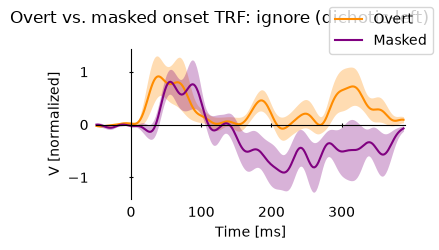

In [55]:
# Overt and masked onset TRFs of the ignored speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: ignore (dichotic-left)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [56]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               56     0.0009177
02        overt               52     0.0004424
03        overt               41     0.0005438
04        overt               41     0.0004296
05        overt               58      0.001038
06        overt               41      0.004097
07        overt               45     6.393e-05
08        overt               41      0.001767
09        overt               54     0.0009665
10        overt               64      0.005638
11        overt               56      0.001182
12        overt               41    -0.0005169
13        overt               43     0.0003955
01        masked              64      0.001873
02        masked              56     0.0008053
03        masked              66      0.002325
04        masked              76     0.0002339
05        masked              56      0.002163
06        masked              45      0.002183
07        masked              80      0.00418

In [57]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='ignore positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='ignore negative peak latency: overt vs. masked'))

,masked
overt,t12 = -4.65*** p < .001


,masked
overt,t12 = -7.02*** p < .001


In [58]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='ignore positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='ignore negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = -0.17 p = .870


,masked
overt,t12 = 1.70 p = .116


In [ ]:
# Stream x masking interaction on peak amplitude (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: stream x masking interaction, F(1,25) = 24.45, p < .001 - overt onsets show no early attention effect, masked onsets do.
dss = []
for stream_name, is_attend in (('attend', True), ('ignore', False)):
    for masking_name in ('overt', 'masked'):
        prefix = '' if is_attend else 'bg_'
        column = f'{prefix}gammatone_on_{masking_name}_inmix_8'
        ds = extract_trf(data_masked, column)
        ds[:, 'stream'] = stream_name
        ds[:, 'masking'] = masking_name
        dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by=('stream', 'masking'))
display(test.ANOVA('positive_amp', 'stream * masking * subject', data=data, title='stream x masking interaction (dichotic-left)'))

## Dichotic Left (intensity-level control)

### Overt and masked onsets together

Overt and masked onsets are made from the same syllable starts, so they rise and fall together. Removed one at a time (the tests above), each can stand in for the other, and both can look useless even when the speaker's onsets matter. Here both are removed at once: if the speaker's onsets add predictive power, this joint test should show it, as the unsplit onset does (the reference tests below, the same onsets unsplit, at the speaker's level in the mixture).

- Joint test significant, one-at-a-time tests not: the information is there, but overt and masked cannot be told apart in these data.
- Joint test not significant either: the overt/masked predictors carry less than the unsplit onsets.

In [ ]:
# Overt + masked onsets attend, together (dichotic-left)
# both of the attended speaker's onset predictors removed at once
data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_MASKED_NO_ATTEND_ONSETS, 'dichotic-left')
show_topomap_trio(data, diff, result, 'Overt + masked onsets attend, together', 'dichotic-left', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets attend, together (dichotic-left): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Overt + masked onsets attend, together', 'dichotic-left')

In [ ]:
# Overt + masked onsets ignore, together (dichotic-left)
# both of the ignored speaker's onset predictors removed at once
data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_MASKED_NO_IGNORE_ONSETS, 'dichotic-left')
show_topomap_trio(data, diff, result, 'Overt + masked onsets ignore, together', 'dichotic-left', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets ignore, together (dichotic-left): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Overt + masked onsets ignore, together', 'dichotic-left')

In [ ]:
# Onset attend at its level in the mixture (dichotic-left)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = compute_direct_comparison(FULL_INMIX, FULL_INMIX_NO_ATTEND_ONSET, 'dichotic-left')
show_topomap_trio(data, diff, result, 'Onset attend at its level in the mixture', 'dichotic-left', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend at its level in the mixture (dichotic-left): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Onset attend at its level in the mixture', 'dichotic-left')

In [ ]:
# Onset ignore at its level in the mixture (dichotic-left)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = compute_direct_comparison(FULL_INMIX, FULL_INMIX_NO_IGNORE_ONSET, 'dichotic-left')
show_topomap_trio(data, diff, result, 'Onset ignore at its level in the mixture', 'dichotic-left', None)

In [ ]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore at its level in the mixture (dichotic-left): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

In [ ]:
p = show_subject_swarm(diff, 'Onset ignore at its level in the mixture', 'dichotic-left')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


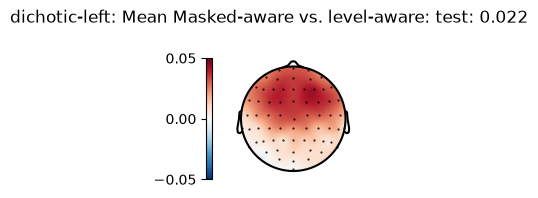

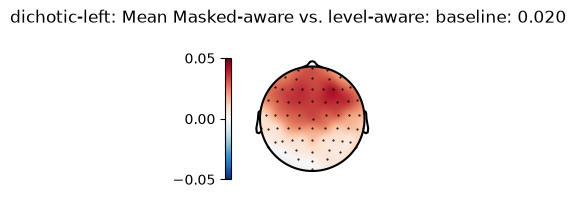

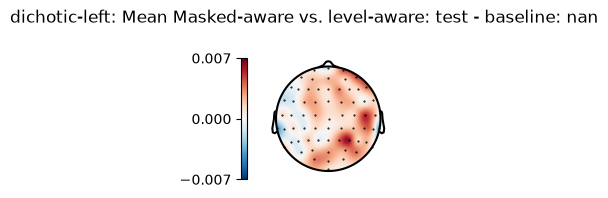

In [60]:
# Masked-aware vs. level-aware (dichotic-left)
# Brodbeck et al. 2020 ran this comparison too: the ignored-speaker-aware model still beat the loudness-only model, t = 9.21, p < .001 - the masking effect isn't just about volume.
data, diff, result = compute_direct_comparison(FULL_MASKED, LEVEL_AWARE, 'dichotic-left')
show_topomap_trio(data, diff, result, 'Masked-aware vs. level-aware', 'dichotic-left', None)

In [61]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked-aware vs. level-aware (dichotic-left): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, pmin=0.05, 2 clusters, p = .256>

Masked-aware vs. level-aware (dichotic-left): ROI model comparison t(12) = 0.828, p = 0.2119


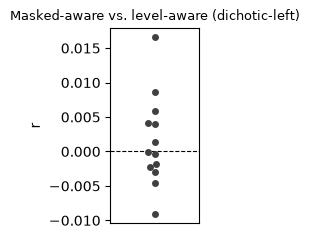

In [62]:
p = show_subject_swarm(diff, 'Masked-aware vs. level-aware', 'dichotic-left')